## Bivariate Analysis — Preparation for Linear Regression

### Research Question
Is sleep duration linearly associated with productivity score?

### Variables
- X: sleep_hours
- Y: productivity_score

### Method
Scatterplot, followed by covariance and Pearson correlation.

In [3]:
import pandas as pd
df = pd.read_csv(r"C:\Users\HP\Downloads\Dataset_digital_life_impact_on_habits\social_media_sleep_stress_productivity_11000.csv")


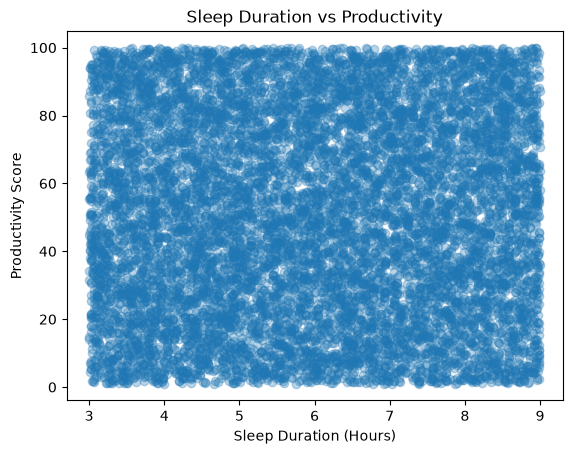

In [13]:
import matplotlib.pyplot as plt

plt.scatter(
    df["sleep_hours"],
    df["productivity_score"],
    alpha=0.3
)

plt.xlabel("Sleep Duration (Hours)")
plt.ylabel("Productivity Score")
plt.title("Sleep Duration vs Productivity")

plt.show()


### Interpretation — Sleep Duration vs Productivity

The scatterplot shows observations distributed across a broad rectangular region, with sleep duration ranging approximately from 3 to 9 hours and productivity scores ranging from 1 to 100.

No clear positive or negative linear trend is visually apparent.

At similar sleep durations, productivity scores vary considerably, suggesting that sleep duration alone may have limited ability to explain productivity variation through a simple linear model.

However, visual inspection alone is insufficient to quantify the relationship.

**Next Step:** Calculate covariance and Pearson correlation to determine the direction and strength of the linear association before fitting a regression model.

### Covariance Analysis

Research Question:
Do sleep duration and productivity scores tend to vary together?

Method:
Sample covariance calculated using the mathematical formula.

In [6]:
# Select the two variables
paired_data = df[["sleep_hours", "productivity_score"]].dropna()

x = list(paired_data["sleep_hours"])
y = list(paired_data["productivity_score"])

n = len(x)

# Calculate means manually
mean_x = sum(x) / n
mean_y = sum(y) / n

# Calculate sum of products of deviations
total = 0

for i in range(n):
    total += (x[i] - mean_x) * (y[i] - mean_y)

# Sample covariance
covariance = total / (n - 1)

print(f"Covariance: {covariance:.4f}")
print(
    paired_data["sleep_hours"].cov(
        paired_data["productivity_score"]
    )
)

Covariance: 0.7934
0.7934241987784018


In [7]:
# Sum of squared deviations
sum_x = 0
sum_y = 0

for i in range(n):
    sum_x += (x[i] - mean_x) ** 2
    sum_y += (y[i] - mean_y) ** 2

# Sample standard deviations
std_x = (sum_x / (n - 1)) ** 0.5
std_y = (sum_y / (n - 1)) ** 0.5

# Pearson correlation formula
correlation = covariance / (std_x * std_y)

print(f"Pearson Correlation: {correlation:.4f}")

Pearson Correlation: 0.0159


In [8]:
# Calculate variance of X using the formula
sum_squared_x = 0

for i in range(n):
    sum_squared_x += (x[i] - mean_x) ** 2

variance_x = sum_squared_x / (n - 1)

# Calculate slope
b1 = covariance / variance_x

# Calculate intercept
b0 = mean_y - b1 * mean_x

print(f"Slope: {b1:.4f}")
print(f"Intercept: {b0:.4f}")

print(f"Regression equation: Y = {b0:.4f} + ({b1:.4f})X")

Slope: 0.2646
Intercept: 49.0346
Regression equation: Y = 49.0346 + (0.2646)X
